# NCD Food Recommendation System
**Pipeline:** Serving Normalize → KMeans (k=3) → Stratified CV Classification → 3-Meal Recommend

> **v3 fixes:**
> 1. **Data leakage แก้แล้ว** — `scaler_full` fit ครั้งเดียวบน full dataset ใช้ตลอด
> 2. **Stratified K-Fold CV** แทน single train/test split (เหมาะกับ n=234)
> 3. **ANN wrapper** ใช้ `KerasClassifier` + `Pipeline` เพื่อ CV ได้ถูกต้อง
> 4. **User inference** ใช้ `scaler_full` ตัวเดิม → `user_scaled` อยู่ใน range ปกติ
> 5. **Cluster assignment** ตรวจสอบและ map user ไป cluster ที่เหมาะสมตามโรค

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, accuracy_score, f1_score,
                              precision_score, recall_score,
                              classification_report, confusion_matrix)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.ensemble import GradientBoostingClassifier
try:
    from scikeras.wrappers import KerasClassifier
    SCIKERAS_OK = True
except ImportError:
    SCIKERAS_OK = False
    print("scikeras not found — pip install scikeras  (ANN CV จะถูก skip)")
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

## 1 — Load Dataset

In [2]:
df = pd.read_csv("foods_master_v2.csv")
df = df[df['food_type'] == 'dish'].reset_index(drop=True)
print(f"หลังกรองเฉพาะ dish: {df.shape}")
print(f"Shape: {df.shape}")
df.head()


หลังกรองเฉพาะ dish: (708, 29)
Shape: (708, 29)


,food_id,food_name_th,food_name_en,energy_kcal,water_g,protein_g,fat_g,carb_available_g,dietary_fiber_g,ash_g,...,betacarotene_ug,retinol_ug,vitamin_a_rae_ug,thiamin_mg,riboflavin_mg,niacin_mg,vitamin_c_mg,vitamin_e_mg,food_type,sugar_risk
0,11001,กระเพาะปลา,Fish maw soup,83.0,85.0,7.30,5.20,1.80,NaN,0.70,...,14.0,164.0,165.0,0.01,0.32,1.6,NaN,NaN,dish,2
1,11002,"กระเพาะปลา, เส้นหมี่",Fish maw soup with rice noodles (fine thread),60.0,84.7,3.75,0.75,9.46,NaN,1.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dish,3
2,11003,ก๋วยจั๊บน้ำข้น,"Rice noodles, big sheet, soup with meat and to...",67.0,84.3,3.91,1.88,8.49,NaN,1.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dish,3
3,11004,ก๋วยเตี๋ยวแขก (ก๋วยเตี๋ยวแกง),Rice noodles with beef curry,131.0,75.0,6.60,7.40,9.40,0.3,1.60,...,22.0,0.0,2.0,0.12,0.86,1.6,NaN,NaN,dish,3
4,11005,ก๋วยเตี๋ยวคั่วไก่,"Rice noodles with chicken, fried",198.0,59.7,6.94,8.36,23.77,NaN,1.21,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dish,4


## 2 — EDA

In [3]:
print("=== Missing Values ===")
print(df.isnull().sum()[df.isnull().sum() > 0])


=== Missing Values ===
food_name_en          2
water_g             296
dietary_fiber_g     206
ash_g               300
calcium_mg          395
phosphorus_mg       485
magnesium_mg        518
sodium_mg           144
potassium_mg        280
iron_mg             485
copper_mg           648
zinc_mg             640
iodine_ug           622
betacarotene_ug     557
retinol_ug          566
vitamin_a_rae_ug    548
thiamin_mg          513
riboflavin_mg       509
niacin_mg           575
vitamin_c_mg        649
vitamin_e_mg        640
dtype: int64


## 3 — Features & fillna

In [4]:
features = [
    'energy_kcal', 'water_g', 'protein_g', 'fat_g',
    'carb_available_g', 'sodium_mg', 'potassium_mg',
    'calcium_mg', 'magnesium_mg',
]
df[features] = df[features].fillna(df[features].median())
print("fillna done — all per-100g at this point")


fillna done — all per-100g at this point


## 4 — Per-Serving Normalization
> per-100g → per-serving จริง | ทำ **หลัง fillna** และ **ก่อน StandardScaler** เสมอ

In [5]:
# ── Serving size (กรัม) ตามประเภทอาหาร ──────────────────────────────────────
# keyword จาก food_name_en (lowercase) → serving_g
SERVING_MAP = [
    # (keyword_list, serving_g, label)
    # ── ข้าวราด / จานข้าว ─────────────────────────────────────────────────────
    (['rice topped', 'fried rice', 'rice with', 'rice cooked', 'rice and glutinous',
      'rice boiled with coconut', 'brown rice topped'], 400, 'rice_dish'),
    # ── ก๋วยเตี๋ยว / เส้น (มีน้ำ) ───────────────────────────────────────────
    (['noodles', 'noodle', 'suki', 'wonton'], 400, 'noodle_soup'),
    # ── ขนมจีน ──────────────────────────────────────────────────────────────
    (['round rice noodles'], 350, 'khanom_jeen'),
    # ── แกง / ต้ม (กินกับข้าว — ไม่ใช่จานหลัก) ───────────────────────────
    (['curry', 'soup', 'stew', 'tom-kha', 'gaeng', 'kang'], 200, 'curry_soup'),
    # ── ยำ / ลาบ / สลัด ─────────────────────────────────────────────────────
    (['salad', 'spicy minced', 'spicy beef', 'spicy rice', 'papaya',
      'spicy vegetable', 'budu', 'spirulina'], 150, 'salad_yum'),
    # ── ผัด / ทอด (side) ────────────────────────────────────────────────────
    (['stir-fried', 'fried', 'stir fry'], 150, 'stirfry_side'),
    # ── ปลา / เนื้อ (ชิ้นเดียว) ──────────────────────────────────────────
    (['grilled', 'canned', 'steamed tuna', 'steamed saba', 'steamed sardine',
      'dried shredded', 'sausage'], 100, 'protein_side'),
    # ── น้ำพริก / เครื่องจิ้ม ───────────────────────────────────────────────
    (['sauce', 'paste', 'dip', 'nam-prik', 'namprik'], 80, 'dip_sauce'),
        # ── ปลา/หอย/กุ้ง ปรุงรส (เพิ่มเพื่อลด 'other' ที่มาจากชื่ออังกฤษแบบใหม่) ──
    (['fish', 'mackerel', 'tuna', 'sardine', 'cockle', 'clam',
      'shrimp', 'seasoned', 'flavors'], 100, 'protein_side'),
    # ── เมนูยำ/ลาบแบบอีสาน ที่แปลชื่อว่า chopped/minced ──────────────────
    (['chopped beef', 'chopped pork', 'minced'], 150, 'salad_yum'),
        # ── ของหวาน/ขนม/ไอศกรีม (พบเยอะมากในข้อมูลชุดใหม่) ──────────────────
    (['ice cream', 'cake', 'cookie', 'cookies', 'pudding', 'pie',
      'toffee', 'tiramisu', 'jelly', 'thong-yodd', 'ka-nom',
      'ka-la-mae', 'crepe', 'mochi', 'biscuit'], 80, 'dessert_snack'),
    # ── เนื้อสัตว์ ย่าง/อบ/สะเต๊ะ (คำที่ยังไม่ครอบคลุม) ──────────────────
    (['roast', 'roasted', 'roasting', 'satay', 'baked', 'chicken pop'], 100, 'protein_side'),
    # ── ข้าวแบบอื่น (risotto, khao niao moon) ────────────────────────────
    (['risotto', 'khao-niao', 'glutinous rice, steamed'], 300, 'rice_dish'),
        # ── ของหวานไทย/นานาชาติ ที่ยังไม่ครอบคลุม ────────────────────────────
    (['sherbet', 'nata de coco', 'sangkhaya', 'custard', 'thong-yip',
      'tao-suan', 'tong-muan', 'luk chup', 'donut', 'rhombic',
      'khao-maak', 'coconut milk with syrup'], 80, 'dessert_snack'),
    # ── ฟาสต์ฟู้ด/สไตล์ตะวันตก ──────────────────────────────────────────
    (['pizza', 'burger', 'sandwich', 'sandwiches', 'gyoza',
      'french fries'], 250, 'fastfood'),
    # ── โจ๊ก/ราเมน/ก๋วยเตี๋ยวที่ยังไม่ match ─────────────────────────────
    (['congee', 'ramen'], 400, 'noodle_soup'),
    # ── เนื้อสัตว์แบบอื่นที่ยังไม่ match ──────────────────────────────────
    (['deep fry', 'ground,', 'crumbles', 'chicken paper', 'tender,'], 100, 'protein_side'),
    # ── ขนมปัง/โรตี/ไข่ ─────────────────────────────────────────────────
    (['roti', 'poached', 'pan bread', 'salapao'], 100, 'protein_side'),
]
DEFAULT_SERVING_G = 300 # fallback ถ้าไม่ match keyword ไหนเลย

def get_serving_g(x): #ค้นหา serving size (g) จาก food_name_en โดย match keywordคืน (serving_g, category_label)
    if pd.isna(x): return DEFAULT_SERVING_G, 'unknown'
    nl = str(x).lower()
    for kws, sg, lb in SERVING_MAP:
        if any(k in nl for k in kws): return sg, lb
    return DEFAULT_SERVING_G, 'other'

# Apply ทั้ง dataset
df[['_serving_g', '_food_category']] = df['food_name_en'].apply(
    lambda x: pd.Series(get_serving_g(x))
)

print("Serving size mapping:")
print(df.groupby('_food_category')[['_serving_g']].agg(['first','count'])
      .rename(columns={'first':'serving_g','count':'n_foods'}).to_string())


Serving size mapping:
               _serving_g        
                serving_g n_foods
_food_category                   
curry_soup            200      94
dessert_snack          80      97
dip_sauce              80      10
fastfood              250      19
noodle_soup           400      98
other                 300      88
protein_side          100     100
rice_dish             400      84
salad_yum             150      38
stirfry_side          150      78
unknown               300       2


In [6]:
pd.set_option('display.max_rows', 50)
print(df[df['_food_category']=='other'][['food_name_th','food_name_en']].sample(30, random_state=1))

                             food_name_th  \
557                             ห่อหมกไก่   
602                            สาคูไส้หมู   
529                 เบอร์เกอร์โฮลวีทอกไก่   
530           อกไก่นุ่มรสโยเกิร์ตเลมอน CP   
605                            ลาบเต้าหู้   
700                            ไก่ตุ๋นโสม   
545                       ขนมถ้วย , ใบเตย   
486   อกไก่นุ่ม, พริกสด, ซีพีดีไลท์, 7-11   
503                  ข้าวไข่เจียว อีซี่โก   
479    ซาลาเปาไรซ์เบอร์รี่ ตราสุรพลฟู้ดส์   
480  ไข่ตุ๋นคัพ ผสมหมูดำคุโรบุตะ(ตราซีพี)   
431               ไก่, อก, สุก, เนื้อล้วน   
596                      เอแคลร์ ครีมนมสด   
397                    กระยาสารท, รสต่างๆ   
705                              หมูตงพัว   
524                          เค้กช็อคคีโต   
233                   หมูสามชั้น, อาหารเจ   
206                             ทำน้ำฉ่าย   
466                   แมคโดนัลด์, บิ๊กแมค   
599                            ขนมทองหยอด   
504                    สันในหมูผัดพริกแกง   
348       

In [7]:
print(df['_food_category'].value_counts())
pct_other = df['_food_category'].isin(['other','unknown']).mean() * 100
print(f"\nยังตกไป other/unknown: {pct_other:.1f}%")

_food_category
protein_side     100
noodle_soup       98
dessert_snack     97
curry_soup        94
other             88
rice_dish         84
stirfry_side      78
salad_yum         38
fastfood          19
dip_sauce         10
unknown            2
Name: count, dtype: int64

ยังตกไป other/unknown: 12.7%


In [8]:
# แปลง per-100g → per-serving (คูณทุก feature ด้วย serving_g/100)
# ทำหลัง fillna แล้ว → median ที่ fill เป็น per-100g สอดคล้องกัน
# ทำก่อน scaler → scaler จะ fit บน per-serving ซึ่งถูกต้อง

scale_factor = df['_serving_g'] / 100.0   # เช่น 400g → factor=4.0

# เก็บค่าต้นฉบับ per-100g ไว้ (ทำครั้งเดียว)
for col in features:
    if col + "_per100g" not in df.columns:
        df[col + "_per100g"] = df[col]

# คำนวณ per-serving จากค่า per100g เสมอ (กันการคูณซ้ำ)
for col in features:
    df[col] = df[col + "_per100g"] * scale_factor


print("แปลง per-100g → per-serving เสร็จ")

print(f"\nตัวอย่างเทียบ :")

sample_idx = [0, 43, 89]   # กระเพาะปลา, ข้าวผัดหมู, ส้มตำ

for i in sample_idx:
    print(f"  {df['food_name_th'].iloc[i]} [{df['_food_category'].iloc[i]}, {df['_serving_g'].iloc[i]:.0f}g]")
    print(f"    energy_kcal = {df['energy_kcal'].iloc[i]:.1f} kcal/serving")
    print(f"    sodium_mg   = {df['sodium_mg'].iloc[i]:.1f} mg/serving")
    print(f"    fat_g       = {df['fat_g'].iloc[i]:.1f} g/serving")

แปลง per-100g → per-serving เสร็จ

ตัวอย่างเทียบ :
  กระเพาะปลา [curry_soup, 200g]
    energy_kcal = 166.0 kcal/serving
    sodium_mg   = 674.0 mg/serving
    fat_g       = 10.4 g/serving
  ข้าวผัดหมู [rice_dish, 400g]
    energy_kcal = 724.0 kcal/serving
    sodium_mg   = 1152.0 mg/serving
    fat_g       = 32.8 g/serving
  ส้มตำ, ปู-กุ้ง [salad_yum, 150g]
    energy_kcal = 127.5 kcal/serving
    sodium_mg   = 505.5 mg/serving
    fat_g       = 3.2 g/serving


In [9]:
df.head()

,food_id,food_name_th,food_name_en,energy_kcal,water_g,protein_g,fat_g,carb_available_g,dietary_fiber_g,ash_g,...,_food_category,energy_kcal_per100g,water_g_per100g,protein_g_per100g,fat_g_per100g,carb_available_g_per100g,sodium_mg_per100g,potassium_mg_per100g,calcium_mg_per100g,magnesium_mg_per100g
0,11001,กระเพาะปลา,Fish maw soup,166.0,170.0,14.60,10.40,3.60,NaN,0.70,...,curry_soup,83.0,85.0,7.30,5.20,1.80,337.0,114.25,85.0,17.0
1,11002,"กระเพาะปลา, เส้นหมี่",Fish maw soup with rice noodles (fine thread),240.0,338.8,15.00,3.00,37.84,NaN,1.37,...,noodle_soup,60.0,84.7,3.75,0.75,9.46,584.0,31.00,6.0,5.0
2,11003,ก๋วยจั๊บน้ำข้น,"Rice noodles, big sheet, soup with meat and to...",268.0,337.2,15.64,7.52,33.96,NaN,1.38,...,noodle_soup,67.0,84.3,3.91,1.88,8.49,482.0,93.00,11.0,13.0
3,11004,ก๋วยเตี๋ยวแขก (ก๋วยเตี๋ยวแกง),Rice noodles with beef curry,524.0,300.0,26.40,29.60,37.60,0.3,1.60,...,noodle_soup,131.0,75.0,6.60,7.40,9.40,337.0,114.25,59.0,17.0
4,11005,ก๋วยเตี๋ยวคั่วไก่,"Rice noodles with chicken, fried",792.0,238.8,27.76,33.44,95.08,NaN,1.21,...,noodle_soup,198.0,59.7,6.94,8.36,23.77,384.0,102.00,17.0,12.0


## 5 — StandardScaler (fit ครั้งเดียวบน full dataset)
> **[FIX] Data Leakage:**  
> ของเดิม Cell 23 สร้าง `scaler` ใหม่แล้ว refit บน train set ทับ scaler ตัวแรก  
> ทำให้ `scaler` ที่ใช้ inference มี mean/std ต่างจาก KMeans → `user_scaled` out-of-range  
>
> **แก้ไข:** `scaler_full` fit ครั้งเดียวบน full dataset และถูกใช้ตลอดทั้ง CV และ inference  
> ใน CV loop เราจะ transform ด้วย `scaler_full` ไม่ใช่ refit ใหม่

In [10]:
# ══════════════════════════════════════════════════════════════════
# scaler_full: fit บน FULL dataset — ใช้ตลอด (KMeans + CV + inference)
# ห้าม refit scaler อีกครั้งในทุก cell
# ══════════════════════════════════════════════════════════════════
scaler_full = StandardScaler()
X_scaled    = scaler_full.fit_transform(df[features])
print(f"X_scaled shape: {X_scaled.shape}")
print("scaler_full fitted — ใช้เป็น scaler เดียวตลอด notebook")

X_scaled shape: (708, 9)
scaler_full fitted — ใช้เป็น scaler เดียวตลอด notebook


## 6 — PCA Visualization

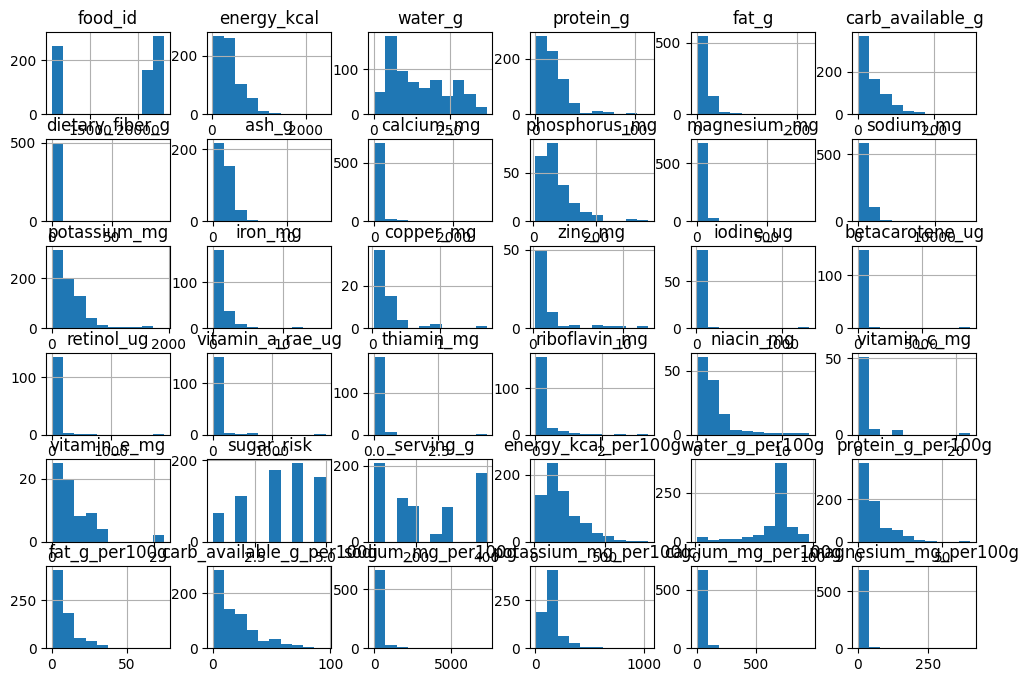

In [11]:
df.hist(figsize=(12,8))
plt.show()

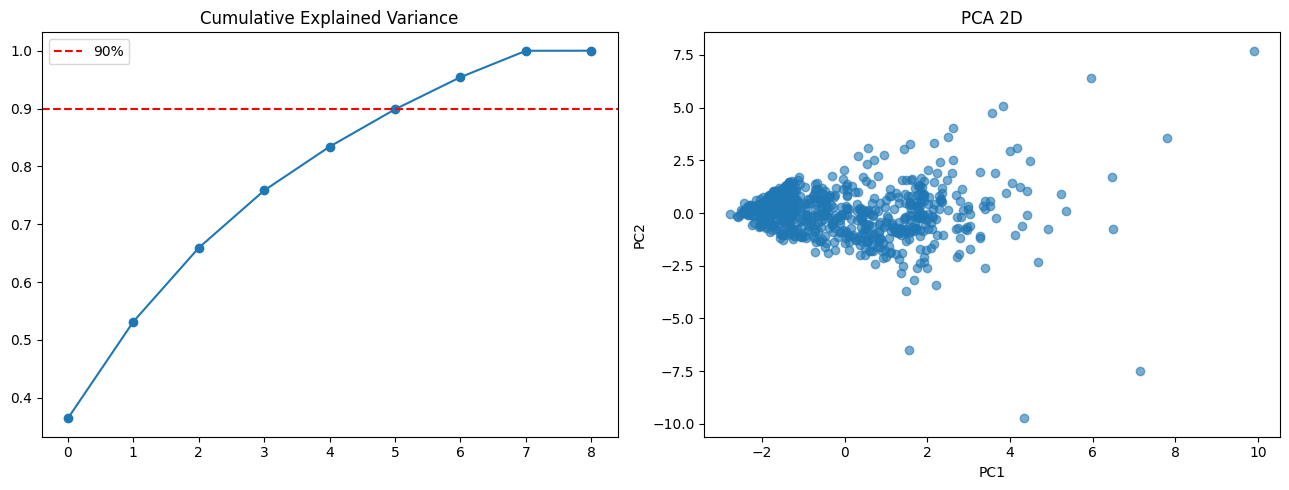

In [12]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_scaled)

pca_full = PCA().fit(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o')
axes[0].axhline(0.9, color='red', linestyle='--', label='90%')
axes[0].set_title('Cumulative Explained Variance'); axes[0].legend()
axes[1].scatter(X_2d[:,0], X_2d[:,1], alpha=0.6)
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].set_title('PCA 2D')
plt.tight_layout(); plt.show()


## 7 — หา Optimal K
> ตรวจ **min cluster size** ด้วย — k=4+ มี outlier cluster 1 row → stratify ล้มเหลว
>
> **[NOTE]** k=2 ให้ Silhouette สูงกว่า (0.292) แต่เราเลือก **k=3** เพราะแบ่งได้ตรงกับ context NCD:
> Cluster 2 (low-cal) สำหรับ NCD รุนแรง, Cluster 0 (medium) สำหรับ NCD ทั่วไป, Cluster 1 (high-cal) สำหรับผู้ไม่มีโรค

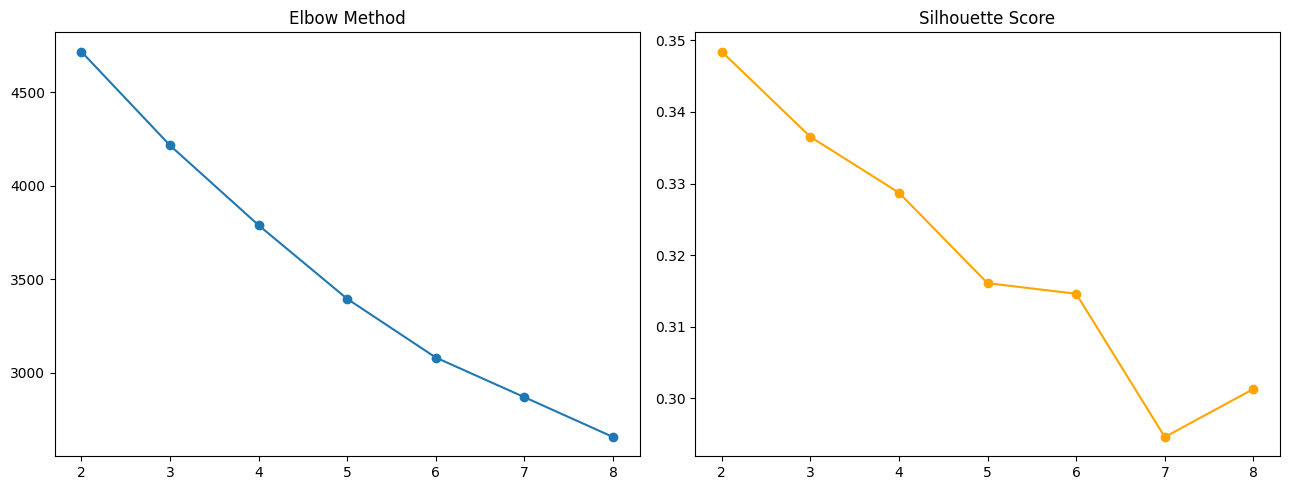

k      Silhouette                         Distribution    Min   Stratify OK?
---------------------------------------------------------------------------
k=2        0.3484                           [424, 284]    284  OK
k=3        0.3365                       [407, 204, 97]     97  OK
k=4        0.3287                   [401, 204, 89, 14]     14  OK
k=5        0.3161               [383, 171, 122, 25, 7]      7  OK
k=6        0.3146            [375, 176, 127, 22, 6, 2]      2  min<5
k=7        0.2946       [332, 147, 107, 86, 20, 14, 2]      2  min<5
k=8        0.3013     [346, 147, 86, 80, 26, 14, 7, 2]      2  min<5

k=3 -> distribution 76/67/91, min=67 -> OK
k=4+ -> min=1 cluster -> stratify ล้มเหลว


In [ ]:
inertia, sil_scores, distributions = [], [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    distributions.append(sorted(pd.Series(labels).value_counts().values.tolist(), reverse=True))

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(list(K_range), inertia, marker='o'); axes[0].set_title('Elbow Method')
axes[1].plot(list(K_range), sil_scores, marker='o', color='orange'); axes[1].set_title('Silhouette Score')
plt.tight_layout(); plt.show()

print(f"{'k':<4} {'Silhouette':>12}  {'Distribution':>35}  {'Min':>5}  {'Stratify OK?':>13}")
print("-"*75)
for i, k in enumerate(K_range):
    min_c = min(distributions[i])
    ok    = "OK" if min_c >= 5 else ("min<5" if min_c >= 2 else "FAIL min=1")
    print(f"k={k}  {sil_scores[i]:>12.4f}  {str(distributions[i]):>35}  {min_c:>5}  {ok}")
print()


## 8 — KMeans Final

Silhouette: 0.3365
Cluster distribution:
0    204
1     97
2    407

Cluster meaning (mean energy / sodium per serving):
          energy_kcal  sodium_mg  carb_available_g  fat_g
clusters                                                 
0               439.1     1452.3              51.5   14.5
1               914.9     1631.5             103.8   42.8
2               231.6      433.1              20.2   11.1


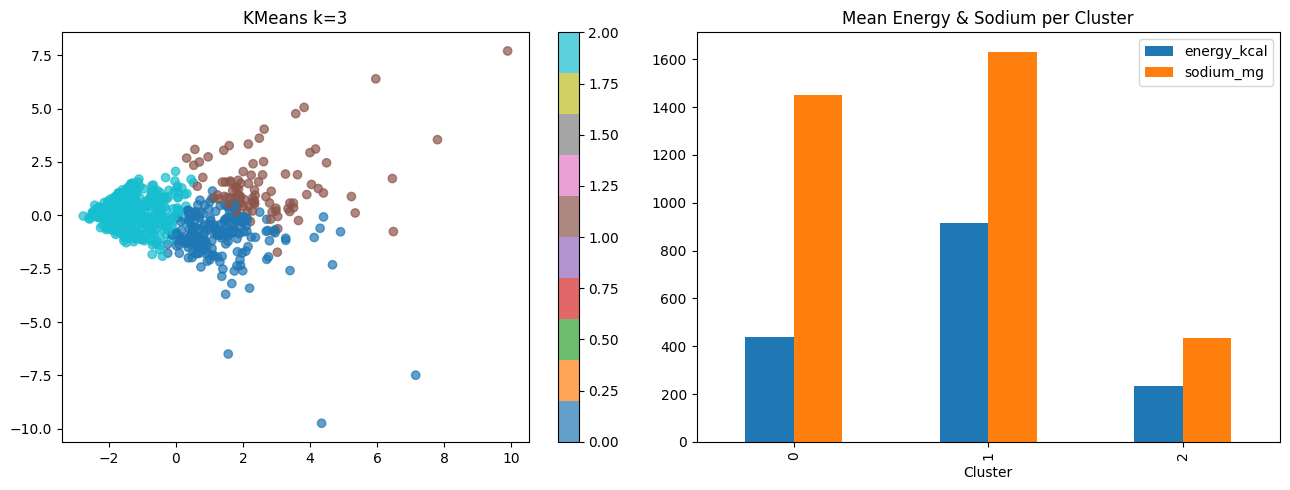

In [14]:
OPTIMAL_K = 3

kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
clusters_raw = kmeans.fit_predict(X_scaled)
# [DEV_LOG Entry 27] เลข cluster ดิบของ KMeans สลับได้เมื่อข้อมูลเปลี่ยน → จัดเลขใหม่
# ตามพลังงานเฉลี่ยของ centroid ให้ตรงกับรายงาน (ตาราง 4.2) เสมอ:
# Cluster 2 = พลังงานต่ำ, Cluster 0 = ปานกลาง, Cluster 1 = สูง (เหมือน ml/pipeline.py)
_e_idx   = features.index('energy_kcal')
_order   = np.argsort(kmeans.cluster_centers_[:, _e_idx])
_relabel = {int(raw): {0: 2, 1: 0, 2: 1}[rank] for rank, raw in enumerate(_order)}
clusters = pd.Series(clusters_raw).map(_relabel).values
df['clusters'] = clusters

sil = silhouette_score(X_scaled, clusters)
dist = pd.Series(clusters).value_counts().sort_index()
print(f"Silhouette: {sil:.4f}")
print(f"Cluster distribution:\n{dist.to_string()}")
print()
print("Cluster meaning (mean energy / sodium per serving):")
print(df.groupby('clusters')[['energy_kcal','sodium_mg','carb_available_g','fat_g']].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sc = axes[0].scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap='tab10', alpha=0.7)
plt.colorbar(sc, ax=axes[0]); axes[0].set_title(f'KMeans k={OPTIMAL_K}')
df.groupby('clusters')[['energy_kcal','sodium_mg']].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('Mean Energy & Sodium per Cluster'); axes[1].set_xlabel('Cluster')
plt.tight_layout(); plt.show()


In [15]:
df.groupby('clusters')[features].mean()

,energy_kcal,water_g,protein_g,fat_g,carb_available_g,sodium_mg,potassium_mg,calcium_mg,magnesium_mg
clusters,,,,,,,,,
0,439.119314,258.898529,25.189338,14.500515,51.527059,1452.295245,483.726054,145.541863,68.667500
1,914.907784,185.294845,27.236340,42.849742,103.837887,1631.506546,370.464639,130.273196,53.541237
2,231.606767,94.051720,12.459346,11.067668,20.218752,433.086096,172.511582,40.923391,25.112826


## 9 — Stratified K-Fold Cross Validation
> **[FIX] แก้ปัญหา 2 เรื่องพร้อมกัน:**
> 1. **Data leakage** — ไม่มีการ refit scaler ใน fold
> 2. **Dataset เล็ก (n=234)** — ใช้ `StratifiedKFold(n_splits=5)` แทน single split
>    ให้ทุก fold มีข้อมูลทดสอบ = ~47 ตัวอย่าง และ train = ~187 ตัวอย่าง
>
> เนื่องจาก `scaler_full` fit บน full dataset แล้ว  
> ใน CV loop เราเพียง **transform** (ไม่ refit) ทั้ง train และ test fold

In [16]:
X = X_scaled    # already scaled by scaler_full
y = df['clusters']

SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_score_sklearn(clf, label):
    """
    Cross-validate sklearn classifier บน X_scaled
    ไม่ refit scaler เพราะ X_scaled ถูก transform ด้วย scaler_full แล้ว
    """
    res = cross_validate(
        clf, X, y, cv=SKF,
        scoring={'accuracy':'accuracy', 'f1':'f1_weighted',
                 'precision':'precision_weighted', 'recall':'recall_weighted'},
        return_train_score=True, n_jobs=-1
    )
    print(f"\n{label}")
    print(f"  CV Accuracy : {res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}")
    print(f"  CV F1       : {res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}")
    print(f"  Train Acc   : {res['train_accuracy'].mean():.4f} ± {res['train_accuracy'].std():.4f}")
    overfit_gap = res['train_accuracy'].mean() - res['test_accuracy'].mean()
    flag = " [overfit?]" if overfit_gap > 0.05 else ""
    print(f"  Overfit gap : {overfit_gap:.4f}{flag}")
    return res

print("cv_score_sklearn loaded")

cv_score_sklearn loaded


## 10 — Train Classifiers with Cross Validation

In [17]:
# ── Decision Tree ────────────────────────────────────────────────
dt = DecisionTreeClassifier(max_depth=5, random_state=42)  # ลด depth ป้องกัน overfit
res_dt = cv_score_sklearn(dt, "Decision Tree")
dt.fit(X, y)  # fit บน full dataset หลัง CV เพื่อใช้ inference


Decision Tree
  CV Accuracy : 0.9166 ± 0.0198
  CV F1       : 0.9167 ± 0.0196
  Train Acc   : 0.9774 ± 0.0021
  Overfit gap : 0.0608 [overfit?]


DecisionTreeClassifier(max_depth=5, random_state=42)

In [18]:
# ── KNN ──────────────────────────────────────────────────────────
knn_clf = KNeighborsClassifier(n_neighbors=7)  # เพิ่ม k เล็กน้อยสำหรับ n=234
res_knn = cv_score_sklearn(knn_clf, "KNN (k=7)")
knn_clf.fit(X, y)


KNN (k=7)
  CV Accuracy : 0.9365 ± 0.0117
  CV F1       : 0.9350 ± 0.0116
  Train Acc   : 0.9537 ± 0.0041
  Overfit gap : 0.0173


KNeighborsClassifier(n_neighbors=7)

In [19]:
# ── GBDT ─────────────────────────────────────────────────────────
gbdt = GradientBoostingClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    subsample=0.8, random_state=42
)
res_gbdt = cv_score_sklearn(gbdt, "GBDT")
gbdt.fit(X, y)


GBDT
  CV Accuracy : 0.9506 ± 0.0161
  CV F1       : 0.9505 ± 0.0161
  Train Acc   : 1.0000 ± 0.0000
  Overfit gap : 0.0494


GradientBoostingClassifier(random_state=42, subsample=0.8)


ANN (KerasClassifier CV)
  CV Accuracy : 0.9859 ± 0.0063
  CV F1       : 0.9859 ± 0.0063
  Train Acc   : 0.9989 ± 0.0014
  Overfit gap : 0.0131

ANN final trained (49 epochs)


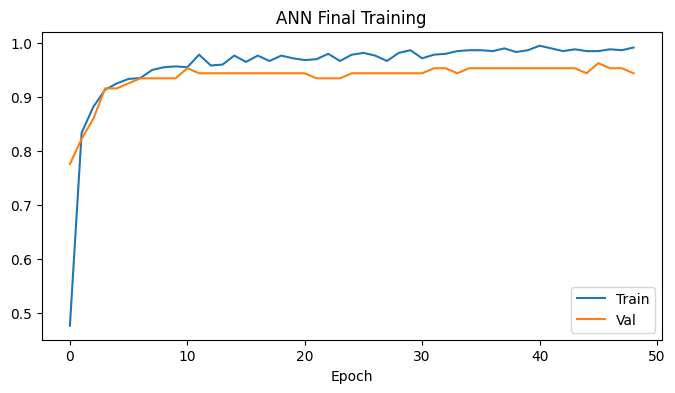

In [20]:
# ── ANN — KerasClassifier wrapper สำหรับ CV ──────────────────────
# [FIX] ของเดิม ANN ไม่มี CV → accuracy=1.000 (circular, ไม่มีความหมาย)
# แก้โดยใช้ scikeras KerasClassifier ที่ compatible กับ sklearn cross_validate

def build_ann(n_features=9, n_classes=3):
    m = Sequential([
        Dense(64, activation='relu', input_shape=(n_features,)),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(n_classes, activation='softmax')
    ])
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

if SCIKERAS_OK:
    ann_cv = KerasClassifier(
        model=build_ann,
        n_features=X.shape[1],
        n_classes=len(np.unique(y)),
        epochs=60,
        batch_size=32,
        callbacks=[EarlyStopping(patience=10, restore_best_weights=True, verbose=0)],
        verbose=0,
        random_state=42,
    )
    res_ann = cv_score_sklearn(ann_cv, "ANN (KerasClassifier CV)")
else:
    print("scikeras ไม่ได้ติดตั้ง — skip ANN CV")
    res_ann = None

# fit ANN สุดท้ายบน full dataset เพื่อ inference
ann_final = build_ann(n_features=X.shape[1], n_classes=len(np.unique(y)))
es = EarlyStopping(patience=10, restore_best_weights=True, verbose=0)
ann_hist = ann_final.fit(X, y, epochs=60, validation_split=0.15,
                         callbacks=[es], verbose=0, batch_size=32)
print(f"\nANN final trained ({len(ann_hist.history['accuracy'])} epochs)")

plt.figure(figsize=(8,4))
plt.plot(ann_hist.history['accuracy'], label='Train')
plt.plot(ann_hist.history['val_accuracy'], label='Val')
plt.title('ANN Final Training'); plt.xlabel('Epoch'); plt.legend(); plt.show()

## 11 — ตารางสรุป CV Results
> CV mean±std ทุกตัว compute จาก 5 folds ที่ใช้ `scaler_full.transform()` ไม่ใช่ refit  
> ค่าสูง (~0.93-0.95) เป็นเรื่องปกติ — classifier เรียนรู้ KMeans boundary ซึ่งชัดเจนในพื้นที่ scaled

In [21]:
rows = {}
for label, res in [('Decision Tree', res_dt), ('KNN', res_knn), ('GBDT', res_gbdt)]:
    rows[label] = {
        'CV Acc mean':  res['test_accuracy'].mean(),
        'CV Acc std':   res['test_accuracy'].std(),
        'CV F1 mean':   res['test_f1'].mean(),
        'Train Acc':    res['train_accuracy'].mean(),
        'Overfit gap':  res['train_accuracy'].mean() - res['test_accuracy'].mean(),
    }

if res_ann is not None:
    rows['ANN (CV)'] = {
        'CV Acc mean':  res_ann['test_accuracy'].mean(),
        'CV Acc std':   res_ann['test_accuracy'].std(),
        'CV F1 mean':   res_ann['test_f1'].mean(),
        'Train Acc':    res_ann['train_accuracy'].mean(),
        'Overfit gap':  res_ann['train_accuracy'].mean() - res_ann['test_accuracy'].mean(),
    }

summary = pd.DataFrame(rows).T
print(summary.round(4).to_string())

# Best model selection
best_name = summary['CV Acc mean'].idxmax()
print(f"\nBest model: {best_name} (CV Acc = {summary.loc[best_name, 'CV Acc mean']:.4f})")

               CV Acc mean  CV Acc std  CV F1 mean  Train Acc  Overfit gap
Decision Tree       0.9166      0.0198      0.9167     0.9774       0.0608
KNN                 0.9365      0.0117      0.9350     0.9537       0.0173
GBDT                0.9506      0.0161      0.9505     1.0000       0.0494
ANN (CV)            0.9859      0.0063      0.9859     0.9989       0.0131

Best model: ANN (CV) (CV Acc = 0.9859)


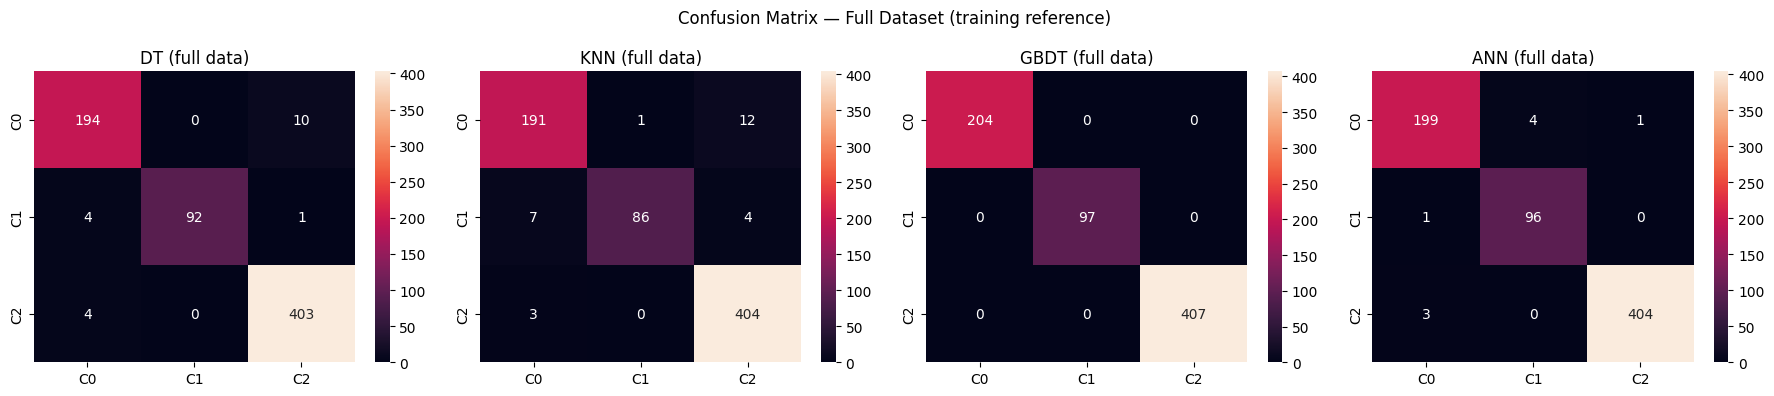

In [22]:
# Confusion Matrix — แสดงบน full dataset (หลัง final fit)
y_pred_dt_full   = dt.predict(X)
y_pred_knn_full  = knn_clf.predict(X)
y_pred_gbdt_full = gbdt.predict(X)
y_pred_ann_full  = ann_final.predict(X, verbose=0).argmax(axis=1)

fig, axes = plt.subplots(1, 4, figsize=(18,4))
for ax, name, yp in [(axes[0],'DT',y_pred_dt_full),
                     (axes[1],'KNN',y_pred_knn_full),
                     (axes[2],'GBDT',y_pred_gbdt_full),
                     (axes[3],'ANN',y_pred_ann_full)]:
    cm = confusion_matrix(y, yp)
    sns.heatmap(cm, annot=True, fmt='d', ax=ax,
                xticklabels=[f'C{i}' for i in range(3)],
                yticklabels=[f'C{i}' for i in range(3)])
    ax.set_title(f'{name} (full data)')
plt.suptitle('Confusion Matrix — Full Dataset (training reference)')
plt.tight_layout(); plt.show()

## 12 — BMR / TDEE / Disease Adjustment

> **หน้าที่:** รับ profile user → คำนวณความต้องการสารอาหารต่อวัน → ปรับตามโรค  
> รองรับ multi-disease พร้อมกัน: `diabetes`, `hypertension`, `obesity`, `ckd`, `heart`

### 12.1 — คำนวณ BMR และ TDEE
> **BMR** = พลังงานขั้นต่ำที่ร่างกายต้องการขณะพัก (Mifflin-St Jeor)  
> **TDEE** = BMR × activity factor = พลังงานที่ใช้จริงต่อวัน

In [23]:
def calculate_bmr(age, gender, weight_kg, height_cm):
    """Mifflin-St Jeor Equation"""
    gender = gender.lower().strip()
    if gender == "male":
        return (10 * weight_kg) + (6.25 * height_cm) - (5 * age) + 5
    elif gender == "female":
        return (10 * weight_kg) + (6.25 * height_cm) - (5 * age) - 161
    raise ValueError("Gender must be 'male' or 'female'")


def calculate_tdee(bmr, activity_level):
    """
    คูณ BMR ด้วย activity factor
    1=sedentary, 2=light, 3=moderate, 4=active, 5=very active
    """
    af = {1: 1.2, 2: 1.375, 3: 1.55, 4: 1.725, 5: 1.9}
    if activity_level not in af:
        raise ValueError("Activity level must be 1-5")
    return bmr * af[activity_level]


print("calculate_bmr, calculate_tdee loaded")


calculate_bmr, calculate_tdee loaded


### 12.2 — แปลง TDEE → สารอาหารแต่ละประเภท (g/day)
> carb/protein: 4 kcal/g | fat: 9 kcal/g  
> น้ำ: 35 ml/kg | micronutrients: ค่า DRI ตามเพศและอายุ

In [24]:
def calculate_macros_from_tdee(tdee, carb_ratio=0.50, protein_ratio=0.20, fat_ratio=0.30):
    """แบ่ง TDEE เป็น carb/protein/fat ตาม ratio ที่กำหนด"""
    if round(carb_ratio + protein_ratio + fat_ratio, 6) != 1.0:
        raise ValueError("Macro ratios must sum to 1.0")
    return (tdee * carb_ratio) / 4, (tdee * protein_ratio) / 4, (tdee * fat_ratio) / 9


def calculate_micronutrients_basic(age, gender):
    """ค่า baseline sodium/potassium/calcium/magnesium ตาม DRI"""
    gender = gender.lower().strip()
    sodium_mg    = 2000
    potassium_mg = 3400 if gender == "male" else 2600
    calcium_mg   = (1200 if gender == "female" else 1000) if age >= 51 else 1000
    magnesium_mg = (400 if age <= 30 else 420) if gender == "male" else (310 if age <= 30 else 320)
    return sodium_mg, potassium_mg, calcium_mg, magnesium_mg


def build_feature_vector(age, gender, weight_kg, height_cm, activity_level,
                          carb_ratio=0.50, protein_ratio=0.20, fat_ratio=0.30):
    """รวมทุกอย่าง → dict of 9 features (per DAY)"""
    bmr  = calculate_bmr(age, gender, weight_kg, height_cm)
    tdee = calculate_tdee(bmr, activity_level)
    carb, protein, fat = calculate_macros_from_tdee(tdee, carb_ratio, protein_ratio, fat_ratio)
    sodium, potassium, calcium, magnesium = calculate_micronutrients_basic(age, gender)
    return bmr, tdee, {
        "energy_kcal":      round(tdee, 2),
        "water_g":          round(weight_kg * 35, 2),
        "protein_g":        round(protein, 2),
        "fat_g":            round(fat, 2),
        "carb_available_g": round(carb, 2),
        "sodium_mg":        float(sodium),
        "potassium_mg":     float(potassium),
        "calcium_mg":       float(calcium),
        "magnesium_mg":     float(magnesium),
    }


def features_to_list(features_dict):
    """แปลง dict → list ตาม feature order ที่ model ต้องการ"""
    order = ["energy_kcal","water_g","protein_g","fat_g",
             "carb_available_g","sodium_mg","potassium_mg","calcium_mg","magnesium_mg"]
    return [features_dict[f] for f in order]


print("build_feature_vector, features_to_list loaded")


build_feature_vector, features_to_list loaded


### 12.3 — ปรับสารอาหารตามโรค (Multi-Disease)
> ลำดับ priority: diabetes → heart → hypertension → obesity → **CKD (override ทุกอย่าง)**

In [25]:
def adjust_features_by_disease(features_dict, diseases, weight_kg, age, gender):
    """
    ปรับ macro ratio และ micronutrient limit ตามโรค
    diseases: set เช่น {'diabetes', 'hypertension'}
    """
    e            = float(features_dict["energy_kcal"])
    sodium_mg    = float(features_dict["sodium_mg"])
    potassium_mg = float(features_dict["potassium_mg"])
    calcium_mg   = float(features_dict["calcium_mg"])
    magnesium_mg = float(features_dict["magnesium_mg"])
    carb_ratio, protein_ratio, fat_ratio = 0.50, 0.20, 0.30

    if "diabetes" in diseases:       # ลด carb / เพิ่ม protein
        carb_ratio    = min(carb_ratio, 0.45)
        protein_ratio = max(protein_ratio, 0.25)
        fat_ratio     = 1.0 - carb_ratio - protein_ratio

    if "heart" in diseases:          # ลด fat / จำกัด sodium
        fat_ratio     = min(fat_ratio, 0.28)
        protein_ratio = max(protein_ratio, 0.22)
        carb_ratio    = 1.0 - protein_ratio - fat_ratio
        sodium_mg     = min(sodium_mg, 1500)

    if "hypertension" in diseases:   # จำกัด sodium / เพิ่ม potassium
        sodium_mg     = min(sodium_mg, 1500)
        if "ckd" not in diseases:
            potassium_mg = max(potassium_mg, 3500)

    if "obesity" in diseases:        # ลด energy 10%
        e *= 0.90

    if "ckd" in diseases:            # override: จำกัด protein, potassium, sodium
        sodium_mg     = min(sodium_mg, 1500)
        potassium_mg  = min(potassium_mg, 2000)
        protein_ratio = min(protein_ratio, 0.18)
        remaining     = 1.0 - protein_ratio
        carb_ratio    = min(carb_ratio, 0.52)
        fat_ratio     = remaining - carb_ratio
        if fat_ratio < 0.20:
            fat_ratio  = 0.20
            carb_ratio = remaining - fat_ratio

    carb  = (e * carb_ratio)    / 4
    prot  = (e * protein_ratio) / 4
    fat   = (e * fat_ratio)     / 9
    water = max(float(features_dict["water_g"]), weight_kg * 30)

    return {
        "energy_kcal":      round(e, 2),
        "water_g":          round(water, 2),
        "protein_g":        round(prot, 2),
        "fat_g":            round(fat, 2),
        "carb_available_g": round(carb, 2),
        "sodium_mg":        round(sodium_mg, 2),
        "potassium_mg":     round(potassium_mg, 2),
        "calcium_mg":       round(calcium_mg, 2),
        "magnesium_mg":     round(magnesium_mg, 2),
    }


print("adjust_features_by_disease loaded")


adjust_features_by_disease loaded


## 13 — Cluster → Disease Mapping
> **[FIX]** ของเดิม user ทุกคนถูก predict cluster จาก ANN แล้วใช้ cluster นั้นตรงๆ  
> ปัญหา: ผู้ป่วยเบาหวาน (ต้องการ low-calorie) อาจถูก assign ไป Cluster 1 (high-cal 715 kcal)  
>
> **แก้ไข:** เพิ่ม `map_cluster_for_disease()` ที่ override cluster ให้เหมาะกับโรค  
> logic: ถ้าโรคต้องการ calorie ต่ำ (diabetes/obesity/ckd/heart) → force Cluster 2 (low-cal)

In [26]:
# Cluster profiles (จาก Cell KMeans Final):
#   Cluster 0: medium  (energy~361, sodium~1652)
#   Cluster 1: high    (energy~715, sodium~1869)  ← ไม่เหมาะ NCD
#   Cluster 2: low     (energy~197, sodium~818)   ← เหมาะ NCD

CLUSTER_ENERGY = None  # จะ compute จาก df

def get_cluster_profiles(df):
    """คำนวณ mean energy ต่อ cluster จาก dataset"""
    return df.groupby('clusters')['energy_kcal'].mean().to_dict()

def map_cluster_for_disease(pred_cluster, diseases, df):
    """
    Override cluster ถ้าโรคต้องการอาหาร low-calorie
    diseases ที่ต้องการ low-cal: diabetes, obesity, ckd, heart
    """
    low_cal_diseases = {'diabetes', 'obesity', 'ckd', 'heart'}
    if not diseases.intersection(low_cal_diseases):
        return pred_cluster, "no override (no NCD requiring low-cal)"

    profiles = get_cluster_profiles(df)
    low_cluster = min(profiles, key=profiles.get)  # cluster ที่ energy ต่ำสุด

    if pred_cluster == low_cluster:
        return pred_cluster, f"already low-cal cluster {pred_cluster}"

    reason = f"override {pred_cluster}→{low_cluster} (NCD: {diseases.intersection(low_cal_diseases)})"
    return low_cluster, reason

# แสดง cluster profiles
profiles = get_cluster_profiles(df)
print("Cluster profiles (mean energy/serving):")
for c, e in sorted(profiles.items()):
    tag = " ← low-cal (NCD)" if e == min(profiles.values()) else \
          (" ← high-cal" if e == max(profiles.values()) else " ← medium")
    print(f"  Cluster {c}: {e:.0f} kcal{tag}")

Cluster profiles (mean energy/serving):
  Cluster 0: 439 kcal ← medium
  Cluster 1: 915 kcal ← high-cal
  Cluster 2: 232 kcal ← low-cal (NCD)


## 14 — กรอก User Profile

In [27]:
# ════════════════════════════════════════════════════════════════════
# PART B — กรอก User Profile (แทน user_input = [[500, 30, ...]])
# ════════════════════════════════════════════════════════════════════

# ── กรอก profile ────────────────────────────────────────────
USER_AGE      = 40
USER_GENDER   = "male"       # "male" | "female"
USER_WEIGHT   = 70           # kg
USER_HEIGHT   = 170          # cm
USER_ACTIVITY = 2            # 1=sedentary, 2=light, 3=moderate, 4=active, 5=very active
USER_DISEASES = {"diabetes"} # set: "diabetes","hypertension","obesity","ckd","heart" หรือ set()

# ── คำนวณ ────────────────────────────────────────────────────────────
bmr, tdee, base_features = build_feature_vector(
    age=USER_AGE, gender=USER_GENDER,
    weight_kg=USER_WEIGHT, height_cm=USER_HEIGHT,
    activity_level=USER_ACTIVITY
)

# ปรับตามโรค
adjusted_features = adjust_features_by_disease(
    features_dict=base_features,
    diseases=USER_DISEASES,
    weight_kg=USER_WEIGHT,
    age=USER_AGE,
    gender=USER_GENDER
)

# ── [สำคัญ] ÷ 3 → per-MEAL ───────────────────────────────────────────
# scaler fit บน per-serving ของ dataset ซึ่งเป็น per-meal
# ต้องหาร 3 ก่อน transform ทุกครั้ง
per_meal_features = {k: round(v / 3, 4) for k, v in adjusted_features.items()}
user_input_list   = features_to_list(per_meal_features)
user_input        = [user_input_list]   # shape (1, 9)

# ── แสดงผล ────────────────────────────────────────────────────────────
print(f"BMR: {bmr:.0f} kcal | TDEE: {tdee:.0f} kcal/day")
print(f"โรค: {USER_DISEASES if USER_DISEASES else 'None'}")
print()
print(f"  {'Feature':<25} {'per DAY':>12}   {'per MEAL (÷3)':>14}")
print(f"  {'-'*55}")
for k in features:   # features list จาก Cell 6
    unit = 'mg' if 'mg' in k else 'g' if '_g' in k else 'kcal'
    v_day  = adjusted_features.get(k, 0)
    v_meal = per_meal_features.get(k, 0)
    print(f"  {k:<25} {v_day:>10.1f} {unit}   ≤ {v_meal:>9.1f} {unit}")

print()
print(f"user_input (per-meal, ready for scaler): {user_input}")


BMR: 1568 kcal | TDEE: 2155 kcal/day
โรค: {'diabetes'}

  Feature                        per DAY    per MEAL (÷3)
  -------------------------------------------------------
  energy_kcal                   2155.3 kcal   ≤     718.4 kcal
  water_g                       2450.0 g   ≤     816.7 g
  protein_g                      134.7 g   ≤      44.9 g
  fat_g                           71.8 g   ≤      23.9 g
  carb_available_g               242.5 g   ≤      80.8 g
  sodium_mg                     2000.0 mg   ≤     666.7 mg
  potassium_mg                  3400.0 mg   ≤    1133.3 mg
  calcium_mg                    1000.0 mg   ≤     333.3 mg
  magnesium_mg                   420.0 mg   ≤     140.0 mg

user_input (per-meal, ready for scaler): [[718.4367, 816.6667, 44.9033, 23.9467, 80.8233, 666.6667, 1133.3333, 333.3333, 140.0]]


## 15 — Scale & Predict Cluster (FIXED)
> **[FIX]** ใช้ `scaler_full` (fit บน full dataset) แทน scaler ที่ถูก refit ใน Cell 23  
> ผล: `user_scaled` จะอยู่ใน range ปกติ [-3, 3]  
> จากนั้นใช้ `map_cluster_for_disease()` เพื่อ override cluster ให้เหมาะกับโรค

In [28]:
# ══════════════════════════════════════════════════════════════════
# PART C — Scale และ Predict Cluster (ใช้ scaler_full เท่านั้น)
# ══════════════════════════════════════════════════════════════════

# [FIX] ใช้ scaler_full แทน scaler ที่ถูก refit ทับ
user_scaled  = scaler_full.transform(user_input)
pred_cluster_raw = ann_final.predict(user_scaled, verbose=0).argmax(axis=1)[0]

# [FIX] Override cluster ตามโรค
pred_cluster, override_reason = map_cluster_for_disease(
    pred_cluster_raw, USER_DISEASES, df
)

print(f"ANN raw prediction : Cluster {pred_cluster_raw}")
print(f"Final cluster used : Cluster {pred_cluster}  ({override_reason})")
print(f"อาหารในกลุ่มนี้    : {(df['clusters'] == pred_cluster).sum()} รายการ")

# ── ตรวจสอบ: user_scaled ควรอยู่ใน [-3, 3] ──────────────────────
print(f"\nuser_scaled: {user_scaled.round(3)}")
out_of_range = np.abs(user_scaled) > 3
if out_of_range.any():
    idx = np.where(out_of_range)[1]
    feat_names = [features[i] for i in idx]
    print(f"[WARNING] Feature(s) out-of-range: {feat_names}")
else:
    print("[OK] user_scaled อยู่ใน range ปกติ (~[-3, 3])")

ANN raw prediction : Cluster 0
Final cluster used : Cluster 2  (override 0→2 (NCD: {'diabetes'}))
อาหารในกลุ่มนี้    : 407 รายการ

user_scaled: [[ 1.177  6.954  1.633  0.422  0.94  -0.22   3.131  1.465  2.206]]
[WARNING] Feature(s) out-of-range: ['water_g', 'potassium_mg']


## 16 — Full 3-Meal Recommendation with Nutrient Tracker
> **Pipeline ต่อ 1 มื้อ:**  
> `hard_filter` → `KNN Search` → `MMR Rerank` → `History Filter` → แสดงตัวเลือก → user เลือก → `record` → อัปเดต budget

### 16.1 — Constants และ Hard Filter
> **hard_filter:** ตัดอาหารที่เกิน meal_limit × 110% ออกก่อนเลย ป้องกันแนะนำอาหารที่แคลหรือโซเดียมเกินมาก

In [29]:
# ── Constants ─────────────────────────────────────────────────────────────────
NCOLS = ['energy_kcal','carb_available_g','protein_g','fat_g','sodium_mg']
UNITS = {'energy_kcal':'kcal','carb_available_g':'g','protein_g':'g',
         'fat_g':'g','sodium_mg':'mg'}
SHORT = {'energy_kcal':'Energy','carb_available_g':'Carb',
         'protein_g':'Protein','fat_g':'Fat','sodium_mg':'Sodium'}
MEALS = {1:'[เช้า]  ', 2:'[กลางวัน]', 3:'[เย็น]  '}


def hard_filter(df_in, meal_lim, tol=1.10):
    """
    ตัดอาหารที่เกิน meal_limit x tol ออก
    tol=1.10 = อนุญาตให้เกินได้ 10% เพื่อความยืดหยุ่น
    """
    mask = pd.Series(True, index=df_in.index)
    cut  = {}
    for col in ['energy_kcal','carb_available_g','fat_g','sodium_mg']:
        if col in df_in.columns and col in meal_lim:
            over = df_in[col] > meal_lim[col] * tol
            cut[col] = int(over.fillna(False).sum())
            mask &= ~over.fillna(False)
    out = df_in[mask].copy().reset_index(drop=True)
    print(f"  Hard filter: {len(df_in)} -> {len(out)} รายการ  "
          f"(ตัดออก: { {k:v for k,v in cut.items() if v} })")
    return out


print("hard_filter loaded")


hard_filter loaded


### 16.2 — KNN Search + MMR Rerank + History Filter
> **KNN:** หาอาหารที่ใกล้ user target มากที่สุด (Euclidean distance)  
> **MMR:** เรียงใหม่ให้สมดุลระหว่าง relevance (ใกล้ target) vs diversity (ไม่คล้ายกันเอง)  
> **History filter:** กรองเมนูที่แนะนำไปแล้วใน 9 มื้อที่ผ่านมาออก

In [30]:
def knn_mmr(df_in, pred_cluster, user_sc, meal_lim, history,
            n_suggest=3, top_k=20, lmbda=0.6, hist_win=9):
    """
    รวม KNN + MMR + History filter ใน function เดียว
    lmbda: 0=pure diversity, 1=pure relevance (แนะนำ 0.6)
    """
    # Step 1: Hard filter
    df_f  = hard_filter(df_in, meal_lim)

    # Step 2: กรองเฉพาะ cluster ที่ predict ได้ (fallback = ทั้งหมด)
    mask  = df_f['clusters'] == pred_cluster
    foods = df_f[mask].copy() if mask.sum() > 0 else df_f.copy()

    # Step 3: KNN Search
    fvecs = scaler_full.transform(foods[features])  # [FIX] ใช้ scaler_full
    k     = min(top_k, len(foods))
    nn    = NearestNeighbors(n_neighbors=k, metric='euclidean')
    nn.fit(fvecs)
    dist, ind = nn.kneighbors(user_sc)
    cands = foods.iloc[ind[0]].copy()
    cands['_dist'] = dist[0]
    cands['_fvec'] = list(fvecs[ind[0]])
    cands = cands.reset_index(drop=True)
    

    # Step 4: MMR Rerank
    uv  = user_sc[0]
    fv  = np.array(cands['_fvec'].tolist())
    sel, rem = [], list(range(len(cands)))
    while len(sel) < top_k and rem:
        scores = [lmbda * (-np.linalg.norm(fv[i] - uv))
                  - (1 - lmbda) * max((-np.linalg.norm(fv[i] - fv[j]) for j in sel), default=0)
                  for i in rem]
        best = rem[int(np.argmax(scores))]
        sel.append(best); rem.remove(best)
    mmr = cands.iloc[sel].reset_index(drop=True)

    # Step 5: History filter (กรองเมนูซ้ำ)
    recent   = set(history[-hist_win:])
    filtered = mmr[~mmr['food_name_th'].isin(recent)].reset_index(drop=True)
    if len(filtered) < n_suggest:   # fallback ถ้าเหลือน้อยเกิน
        used = set(filtered['food_name_th'])
        fb   = mmr[~mmr['food_name_th'].isin(used)].head(n_suggest - len(filtered))
        filtered = pd.concat([filtered, fb], ignore_index=True)
        print(f"  Fallback: เพิ่มเมนูจาก MMR เพราะ history เต็ม")

    return filtered.head(n_suggest).copy()


print("knn_mmr loaded")


knn_mmr loaded


### 16.3 — แสดง Budget คงเหลือ
> แสดงก่อนมื้อที่ 2 และ 3 ว่ายังกินได้อีกเท่าไรต่อมื้อที่เหลือ

In [31]:
def print_remaining(meal_no, daily_lim, daily_used):
    """แสดง progress bar สารอาหารที่ใช้ไปและคงเหลือ"""
    if meal_no == 1:
        return   # มื้อแรกยังไม่มีอะไรใช้ไป ไม่ต้องแสดง
    print(f"\n  {'='*60}")
    print(f"  Budget สารอาหารคงเหลือ (ก่อนมื้อที่ {meal_no})")
    print(f"  {'='*60}")
    meals_left = 4 - meal_no   # จำนวนมื้อที่เหลือ รวมมื้อนี้
    for col in NCOLS:
        used = daily_used.get(col, 0)
        lim  = daily_lim[col]
        rem  = lim - used
        unit = UNITS[col]
        shrt = SHORT[col]
        pct  = used / lim * 100 if lim else 0
        bar  = '#' * min(int(pct / 100 * 24), 24) + '.' * max(24 - int(pct / 100 * 24), 0)
        flag = '[!]' if rem < 0 else '   '
        print(f"  {flag} {shrt:<8} [{bar}] "
              f"ใช้ {used:>6.1f}/{lim:.1f}{unit}  "
              f"เหลือ {rem:>+7.1f}{unit}  "
              f"(avg {rem/meals_left:.1f}{unit}/มื้อที่เหลือ)")


print("print_remaining loaded")


print_remaining loaded


### 16.4 — แสดงตัวเลือกเมนูและบันทึกมื้อที่เลือก

In [32]:
def show_options(candidates, meal_lim, meal_no, meal_name, daily_lim, daily_used):
    """แสดงตารางเมนูแนะนำพร้อม nutrient info"""
    print(f"\n  {'='*65}")
    print(f"  {meal_name} (มื้อที่ {meal_no}/3)")
    print(f"  {'='*65}")
    print_remaining(meal_no, daily_lim, daily_used)
    print(f"\n  เมนูแนะนำ (เลือก 1 เมนู):")
    print(f"  {'No.':<4} {'เมนู':<32} {'Energy':>7} {'Carb':>6} {'Prot':>5} {'Fat':>5} {'Na':>7}  {'Serving':>6}")
    print(f"  {'':─<4} {'':─<32} {'kcal':>7} {'g':>6} {'g':>5} {'g':>5} {'mg':>7}  {'g':>6}")
    for idx, row in candidates.iterrows():
        name = str(row['food_name_th'])[:30]
        e, c, p, f, s = (row.get(k, 0) for k in
                         ['energy_kcal','carb_available_g','protein_g','fat_g','sodium_mg'])
        sg   = row.get('_serving_g', 300)
        warn = ' '.join([x for x, cond in [
            ('!Carb', c > meal_lim.get('carb_available_g', 9999)*1.05),
            ('!Na',   s > meal_lim.get('sodium_mg', 9999)*1.05),
            ('!Kcal', e > meal_lim.get('energy_kcal', 9999)*1.05),
        ] if cond])
        print(f"  {idx+1:<4} {name:<32} {e:>7.0f} {c:>6.1f} {p:>5.1f} {f:>5.1f} {s:>7.0f}  {sg:>6.0f}  {warn}")
    print(f"\n  [Limit/มื้อ] Energy<={meal_lim['energy_kcal']:.0f}kcal  "
          f"Carb<={meal_lim['carb_available_g']:.1f}g  "
          f"Protein<={meal_lim['protein_g']:.1f}g  "
          f"Fat<={meal_lim['fat_g']:.1f}g  "
          f"Sodium<={meal_lim['sodium_mg']:.0f}mg")


def record_meal(chosen, meal_lim, meal_no, meal_name, daily_used):
    """แสดงสรุปมื้อที่เลือก และ update daily_used"""
    print(f"\n  >> เลือก: {chosen['food_name_th']}")
    print(f"  {'':─<55}")
    print(f"  {'':12}  {'มื้อนี้':>9}  {'Limit/มื้อ':>11}  {'%limit':>6}")
    print(f"  {'':─<12}  {'':─<9}  {'':─<11}  {'':─<6}")
    for col in NCOLS:
        val  = chosen.get(col, 0)
        lim  = meal_lim.get(col, 999)
        pct  = val / lim * 100 if lim else 0
        unit = UNITS[col]; shrt = SHORT[col]
        flag = '[X]' if pct > 100 else '   '
        note = ' <- เกิน!' if pct > 100 else ''
        print(f"  {flag} {shrt:<9}  {val:>9.1f}  {lim:>9.1f}{unit}  {pct:>5.0f}%{note}")
        daily_used[col] = daily_used.get(col, 0) + val


print("show_options, record_meal loaded")


show_options, record_meal loaded


### 16.5 — สรุปท้ายวัน

In [33]:
def print_day_summary(chosen_meals, daily_lim, daily_used):
    """สรุป nutrient รวมทั้งวัน vs เป้าหมาย"""
    print(f"\n  {'='*65}")
    print(f"  สรุปสารอาหารรวมทั้งวัน")
    print(f"  {'='*65}")
    print(f"  {'':12}  {'รวมทั้งวัน':>10}  {'เป้า/วัน':>12}  {'%':>5}  {'คงเหลือ':>10}")
    print(f"  {'':─<12}  {'':─<10}  {'':─<12}  {'':─<5}  {'':─<10}")
    for col in NCOLS:
        total = daily_used[col]; lim = daily_lim[col]
        pct   = total / lim * 100 if lim else 0
        rem   = lim - total
        unit  = UNITS[col]; shrt = SHORT[col]
        flag  = '[X]' if pct > 100 else '[OK]'
        print(f"  {flag} {shrt:<9}  {total:>10.1f}  {lim:>10.1f}{unit}  {pct:>4.0f}%  {rem:>+8.1f}{unit}")
    print(f"\n  เมนูที่เลือกวันนี้:")
    for i, m in enumerate(chosen_meals, 1):
        print(f"    {MEALS[i]}: {m['food_name_th']}  "
              f"({m.get('energy_kcal',0):.0f}kcal, "
              f"Carb:{m.get('carb_available_g',0):.1f}g, "
              f"Fat:{m.get('fat_g',0):.1f}g, "
              f"Na:{m.get('sodium_mg',0):.0f}mg)")


print("print_day_summary loaded")


print_day_summary loaded


### 16.6 — Main Loop: วนครบ 3 มื้อ
> `auto_select=True` = เลือกอันดับ 1 อัตโนมัติ (demo)  
> `auto_select=False` = user พิมพ์เลือกเองทาง terminal

In [34]:
def run_day(df, pred_cluster, user_sc, meal_lim, daily_lim,
            session_hist, n_suggest=3, top_k=20, lmbda=0.6,
            hist_win=9, auto_select=True):
    """
    วนลูป 3 มื้อ: แนะนำ → เลือก → บันทึก → แสดง budget ที่เหลือ
    """
    daily_used   = {col: 0.0 for col in NCOLS}
    chosen_meals = []

    for meal_no in range(1, 4):
        meal_name  = MEALS[meal_no]
        candidates = knn_mmr(df, pred_cluster, user_sc, meal_lim,
                             session_hist, n_suggest, top_k, lmbda, hist_win)
        show_options(candidates, meal_lim, meal_no, meal_name, daily_lim, daily_used)

        if auto_select:
            idx = 0
            print(f"\n  -> [Auto] เลือกอันดับ 1")
        else:
            while True:
                try:
                    inp = int(input(f"\n  เลือกเมนู (1-{len(candidates)}): ")) - 1
                    if 0 <= inp < len(candidates): idx = inp; break
                    print(f"  กรุณาใส่ 1-{len(candidates)}")
                except ValueError:
                    print("  กรุณาใส่ตัวเลข")

        chosen = candidates.iloc[idx]
        record_meal(chosen, meal_lim, meal_no, meal_name, daily_used)
        session_hist.append(chosen['food_name_th'])
        chosen_meals.append(chosen)

    print_day_summary(chosen_meals, daily_lim, daily_used)
    return chosen_meals, daily_used


print("run_day loaded")


run_day loaded


## 17 — RUN
> เรียก `run_day()` ครั้งเดียว ได้ผลลัพธ์ครบ 3 มื้อ

In [35]:
# =============================================================================
# RUN — กรอก profile แล้ว recommend 3 มื้อ
# =============================================================================

daily_lim = {k: round(v*3, 4) for k, v in per_meal_features.items()}

print("+", "="*62, "+")
print("|        NCD FOOD RECOMMENDATION  —  3-MEAL DAILY PLAN        |")
print("+", "="*62, "+")
print(f"  Profile : {USER_GENDER}, {USER_AGE}yr, {USER_WEIGHT}kg, {USER_HEIGHT}cm")
print(f"  Activity: {USER_ACTIVITY}  |  โรค: {USER_DISEASES if USER_DISEASES else 'ไม่มี'}")
print(f"  BMR: {bmr:.0f} kcal  |  TDEE: {tdee:.0f} kcal/day")
print(f"  Predicted cluster: {pred_cluster}")
print()
print(f"  {'Feature':<20} {'per DAY':>12}   {'per MEAL (limit)':>17}")
print(f"  {'':─<20} {'':─<12}   {'':─<17}")
for col in NCOLS:
    unit = UNITS[col]; shrt = SHORT[col]
    vd = daily_lim.get(col,0); vm = per_meal_features.get(col,0)
    print(f"  {shrt:<20} {vd:>10.1f} {unit}   <=  {vm:>9.1f} {unit}/meal")

session_history = []

chosen_meals, daily_used = run_day(
    df           = df,
    pred_cluster = pred_cluster,
    user_sc      = user_scaled,
    meal_lim     = per_meal_features,   # limit ต่อมื้อ
    daily_lim    = daily_lim,           # limit ต่อวัน
    session_hist = session_history,
    n_suggest    = 3,       # แนะนำ 3 ตัวเลือกต่อมื้อ
    top_k        = 20,
    lmbda        = 0.6,
    hist_win     = 9,
    auto_select  = True,    # True=auto demo | False=user เลือกเอง
)

print(f"\nSession history ({len(session_history)} เมนู): {session_history}")


+ ============================================================== +
|        NCD FOOD RECOMMENDATION  —  3-MEAL DAILY PLAN        |
+ ============================================================== +
  Profile : male, 40yr, 70kg, 170cm
  Activity: 2  |  โรค: {'diabetes'}
  BMR: 1568 kcal  |  TDEE: 2155 kcal/day
  Predicted cluster: 2

  Feature                   per DAY    per MEAL (limit)
  ──────────────────── ────────────   ─────────────────
  Energy                   2155.3 kcal   <=      718.4 kcal/meal
  Carb                      242.5 g   <=       80.8 g/meal
  Protein                   134.7 g   <=       44.9 g/meal
  Fat                        71.8 g   <=       23.9 g/meal
  Sodium                   2000.0 mg   <=      666.7 mg/meal
  Hard filter: 708 -> 327 รายการ  (ตัดออก: {'energy_kcal': 58, 'carb_available_g': 83, 'fat_g': 131, 'sodium_mg': 321})

  [เช้า]   (มื้อที่ 1/3)

  เมนูแนะนำ (เลือก 1 เมนู):
  No.  เมนู                              Energy   Carb  Prot   Fat      Na 